In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import json
import seaborn as sns
%matplotlib inline
sns.set(style="whitegrid")

In [2]:

csv = pd.read_csv("sales_data_sample.csv", encoding="cp1252")
print("File 1: 'sales_data_sample.csv' loaded.")

File 1: 'sales_data_sample.csv' loaded.


In [3]:
ed = pd.read_excel("Sample-Sales-Data.xlsx")
print("File 2: 'Sample-Sales-Data.xlsx' loaded.")

File 2: 'Sample-Sales-Data.xlsx' loaded.


In [4]:
with open("customers.json", "r") as json_file:
    json_data = json.load(json_file)
print("File 3: 'customers.json' loaded.")

File 3: 'customers.json' loaded.


In [5]:
cust_df = pd.DataFrame(json_data)
print("JSON data has been converted into a DataFrame (cust_df).")

JSON data has been converted into a DataFrame (cust_df).


In [6]:
csv.info()
csv.describe()
csv.shape

<class 'pandas.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   str    
 6   STATUS            2823 non-null   str    
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   str    
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   str    
 13  CUSTOMERNAME      2823 non-null   str    
 14  PHONE             2823 non-null   str    
 15  ADDRESSLINE1      2823 non-null   str    
 16  ADDRESSLINE2      302 non-null    str    
 17  CITY  

(2823, 25)

In [13]:
ed.info()
ed.describe()
ed.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 390 entries, 0 to 389
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Postcode        390 non-null    int64  
 1   Sales_Rep_ID    390 non-null    int64  
 2   Sales_Rep_Name  390 non-null    object 
 3   Year            390 non-null    int64  
 4   Value           390 non-null    float64
dtypes: float64(1), int64(3), object(1)
memory usage: 15.4+ KB


(390, 5)

In [7]:
cust_df.info()
cust_df.describe()
cust_df.shape

<class 'pandas.DataFrame'>
RangeIndex: 9999 entries, 0 to 9998
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          9999 non-null   int64
 1   email       9999 non-null   str  
 2   first       9999 non-null   str  
 3   last        9999 non-null   str  
 4   company     9999 non-null   str  
 5   created_at  9999 non-null   str  
 6   country     9999 non-null   str  
dtypes: int64(1), str(6)
memory usage: 1.4 MB


(9999, 7)

In [8]:
csv['ORDERDATE'] = pd.to_datetime(csv['ORDERDATE'])
csv['TERRITORY'] = csv['TERRITORY'].fillna('Unknown')
csv['YEAR_MONTH'] = csv['ORDERDATE'].dt.to_period('M')

print("Data cleaning completed successfully.")

Data cleaning completed successfully.


In [9]:
total_revenue = csv['SALES'].sum()
print(total_revenue)
product_sales = csv.groupby('PRODUCTLINE')['SALES'].sum().sort_values(ascending=False)
print(product_sales)

customer_trends = csv.groupby('CUSTOMERNAME')['SALES'].sum().sort_values(ascending=False).head(10)
print(customer_trends)

monthly_sales = csv.groupby('YEAR_MONTH')['SALES'].sum()
print(monthly_sales)

10032628.85
PRODUCTLINE
Classic Cars        3919615.66
Vintage Cars        1903150.84
Motorcycles         1166388.34
Trucks and Buses    1127789.84
Planes               975003.57
Ships                714437.13
Trains               226243.47
Name: SALES, dtype: float64
CUSTOMERNAME
Euro Shopping Channel           912294.11
Mini Gifts Distributors Ltd.    654858.06
Australian Collectors, Co.      200995.41
Muscle Machine Inc              197736.94
La Rochelle Gifts               180124.90
Dragon Souveniers, Ltd.         172989.68
Land of Toys Inc.               164069.44
The Sharp Gifts Warehouse       160010.27
AV Stores, Co.                  157807.81
Anna's Decorations, Ltd         153996.13
Name: SALES, dtype: float64
YEAR_MONTH
2003-01     129753.60
2003-02     140836.19
2003-03     174504.90
2003-04     201609.55
2003-05     192673.11
2003-06     168082.56
2003-07     187731.88
2003-08     197809.30
2003-09     263973.36
2003-10     568290.97
2003-11    1029837.66
2003-12     26187

--- Visualization 1: Product-wise Sales ---


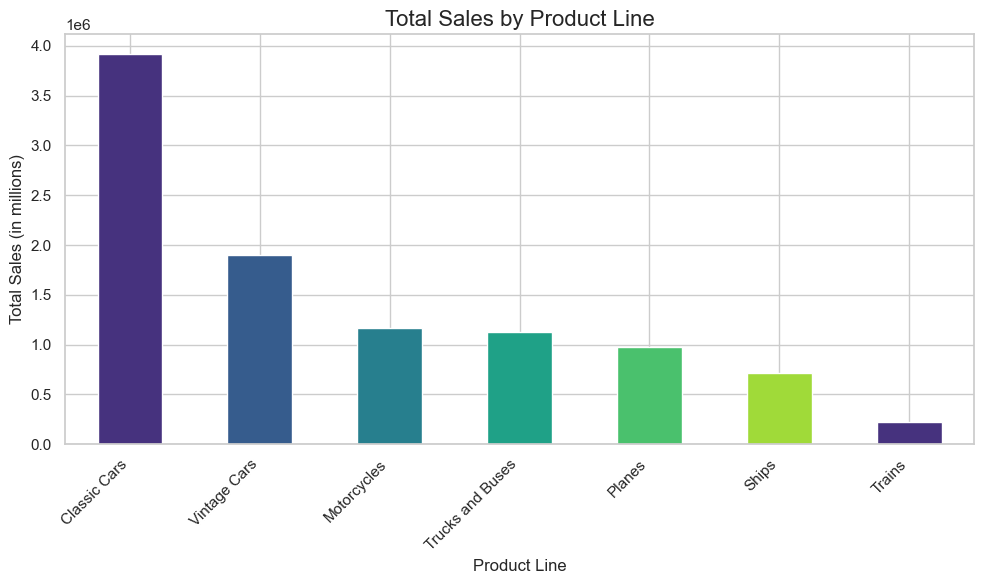

In [10]:
print("--- Visualization 1: Product-wise Sales ---")
plt.figure(figsize=(10, 6))
product_sales.plot(kind='bar', color=sns.color_palette('viridis'))
plt.title('Total Sales by Product Line', fontsize=16)
plt.ylabel('Total Sales (in millions)')
plt.xlabel('Product Line')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


--- Visualization 2: Monthly Sales Trends ---


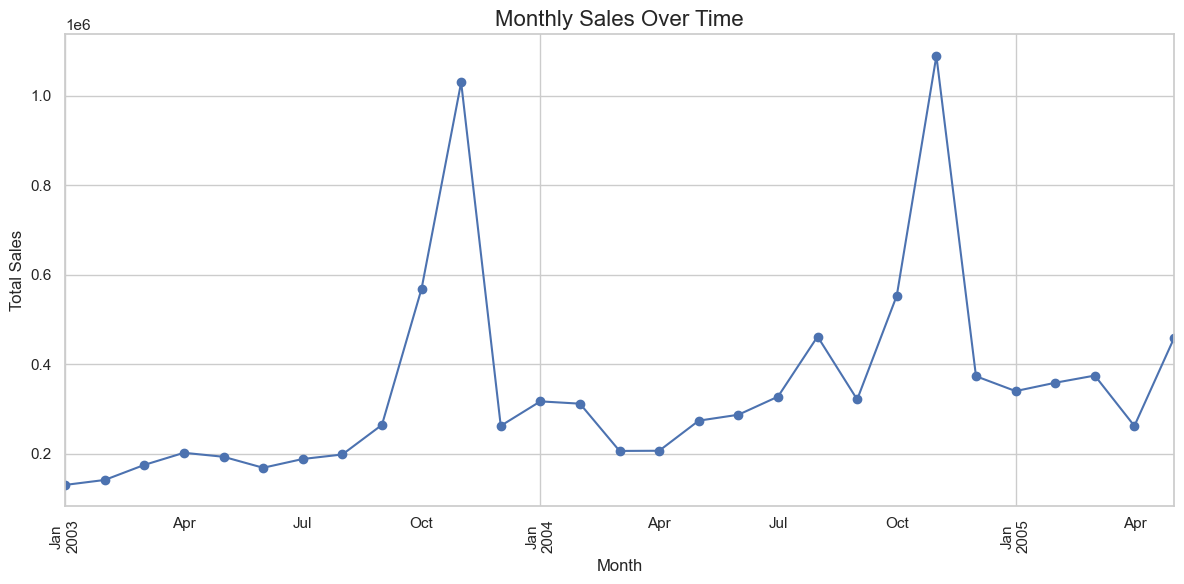

In [11]:
print("\n--- Visualization 2: Monthly Sales Trends ---")
plt.figure(figsize=(12, 6))
monthly_sales.plot(kind='line', marker='o', linestyle='-')
plt.title('Monthly Sales Over Time', fontsize=16)
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()


--- Visualization 3: Sales by Territory ---


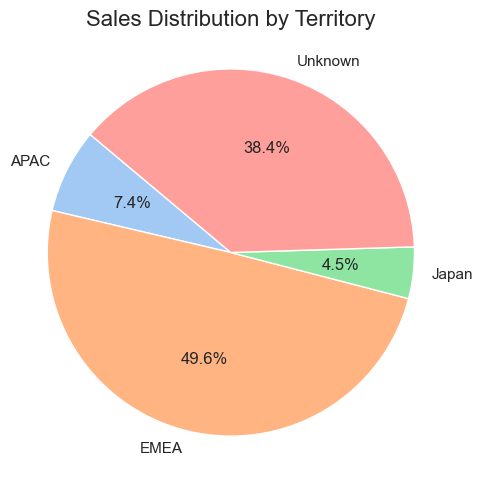

In [19]:
print("\n--- Visualization 3: Sales by Territory ---")

# Calculate the metric for the pie chart
territory_sales = csv.groupby('TERRITORY')['SALES'].sum()

plt.figure(figsize=(5, 5))
territory_sales.plot(kind='pie', autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))

plt.title('Sales Distribution by Territory', fontsize=16)
plt.ylabel('')  # Remove the default y-axis label
plt.axis('equal')  # Ensure the pie chart is drawn as a circle
plt.tight_layout()
plt.show()



--- Visualization 4: Sales Value Distribution ---


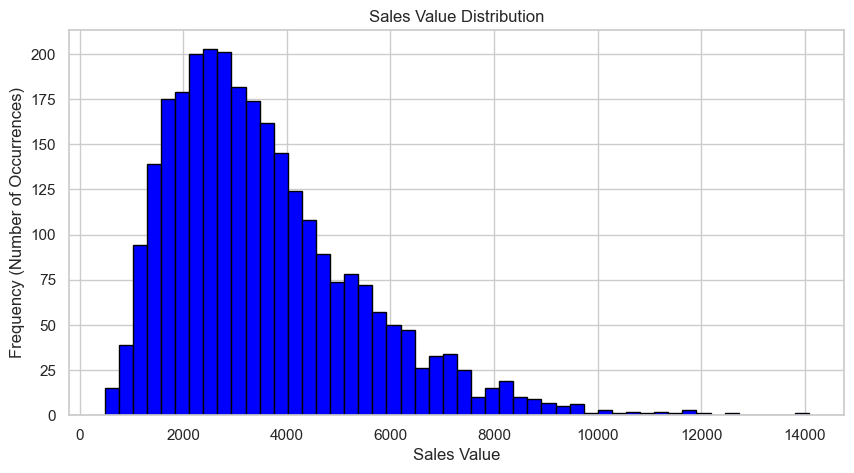

In [20]:

print("\n--- Visualization 4: Sales Value Distribution ---")

csv['SALES'].plot(kind='hist', bins=50, figsize=(10, 5), color='blue', edgecolor='black')

plt.title('Sales Value Distribution')
plt.xlabel('Sales Value')
plt.ylabel('Frequency (Number of Occurrences)')
plt.show()
